In [1]:
import random as rd

Variant = 21
rd.seed(Variant)

Numbers_of_problems = [i+1 for i in rd.sample(range(11),2)]
Numbers_of_problems

[3, 7]

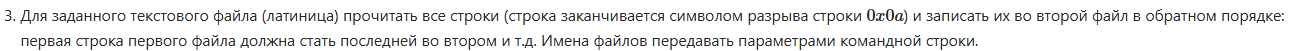

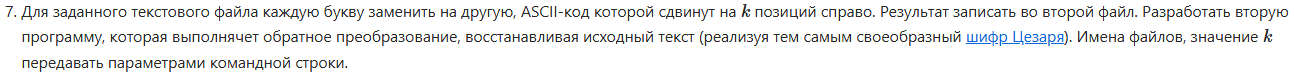

In [1]:
Номер 3

format ELF64

public _start
public input
public read_write
public buffer
public exit

section '.bss' writable
  buffer rb 1024

section '.data' writable
  file_size dq 0
  newline   db 10

section '.text' executable

_start:
  pop rcx
  cmp rcx, 3              ; программа + 2 аргумента
  jl exit

  call input
  call read_write
  jmp exit

input:
   ; --- открыть входной файл (argv[1]) только на чтение ---
   mov rdi, [rsp+16]
   mov rax, 2
   mov rsi, 0              ; O_RDONLY
   syscall
   cmp rax, 0
   jl exit
   mov r8, rax             ; fd_in

   ; --- lseek(fd_in, 0, SEEK_END) → размер файла ---
   mov rax, 8              ; lseek
   mov rdi, r8
   mov rsi, 0
   mov rdx, 2              ; SEEK_END
   syscall
   mov [file_size], rax

   ; --- открыть выходной файл (argv[2]) ---
   mov rdi, [rsp+24]
   mov rax, 2
   mov rsi, 0x241          ; O_WRONLY|O_CREAT|O_TRUNC
   mov rdx, 644
   syscall
   jl exit
   mov r9, rax             ; fd_out

   ret

read_write:
.loop:
   ; --- если осталось < 1024 — дочитываем остаток ---
   cmp qword [file_size], 1024
   jb .last_chunk

   ; --- иначе: вычитаем 1024, ставим позицию, читаем ---
   sub qword [file_size], 1024

   mov rax, 8              ; lseek(fd_in, file_size, SEEK_SET)
   mov rdi, r8
   mov rsi, [file_size]
   mov rdx, 0
   syscall

   mov rax, 0              ; read(fd_in, buffer, 1024)
   mov rdi, r8
   mov rsi, buffer
   mov rdx, 1024
   syscall

   test rax, rax
   jle .cont

   jmp .process

.last_chunk:
   mov rdx, [file_size]
   test rdx, rdx
   jz .cont                ; больше нечего читать

   mov rax, 8              ; lseek(fd_in, 0, SEEK_SET)
   mov rdi, r8
   mov rsi, 0
   mov rdx, 0
   syscall

   mov rax, 0              ; read(fd_in, buffer, file_size)
   mov rdi, r8
   mov rsi, buffer
   mov rdx, [file_size]
   syscall

   test rax, rax
   jle .cont

   mov qword [file_size], 0  ; чтобы второй раз не обработать

.process:
   ; rax = сколько прочитано
   mov r12, rax              ; r12 = «конец» (не включая)
   lea r13, [rax - 1]        ; r13 = сканирующий указатель с конца

.loop_2:
   test r13, r13
   js .done                  ; дошли до начала буфера

   mov bl, byte [buffer + r13]
   cmp bl, 10
   je .carr

   dec r13
   jmp .loop_2

.carr:
   ; в r13 лежит '\n'. Пишем [r13+1, r12) + '\n' (если непусто)
   mov rdx, r12
   sub rdx, r13
   dec rdx                   ; длина = r12 - r13 - 1
   test rdx, rdx
   jz .skip_carr

   lea rsi, [buffer + r13 + 1]
   mov rax, 1
   mov rdi, r9
   syscall

   mov rax, 1                ; '\n'
   mov rdi, r9
   lea rsi, [newline]
   mov rdx, 1
   syscall

.skip_carr:
   mov r12, r13              ; новый «конец»
   dec r13
   jmp .loop_2

.done:
   ; пишем остаток [0, r12) + '\n' (если непусто)
   test r12, r12
   jz .loop

   mov rdx, r12
   mov rsi, buffer
   mov rax, 1
   mov rdi, r9
   syscall

   mov rax, 1                ; '\n'
   mov rdi, r9
   lea rsi, [newline]
   mov rdx, 1
   syscall

   jmp .loop

.cont:
   mov rax, 3
   mov rdi, r8
   syscall

   mov rax, 3
   mov rdi, r9
   syscall

   ret

exit:
   mov rax, 60
   xor rdi, rdi
   syscall


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (119853221.py, line 51)

In [ ]:
Номер 7

format ELF64

public _start
public input
public read_write
public buffer
public exit

section '.bss' writable
  buffer rb 1024

section '.data' writable
  file_size dq 0
  k dq 0

section '.text' executable

_start:
  pop rcx
  cmp rcx, 5
  jl exit

  ; mode = argv[1][0] - '0'
  mov rdi, [rsp+8]
  movzx r12d, byte [rdi]
  sub r12, '0'

  ; k = argv[2][0] - '0'
  mov rdi, [rsp+16]
  movzx rax, byte [rdi]
  sub rax, '0'
  mov [k], rax

  call input
  call read_write
  jmp exit

input:
   ; --- открыть входной файл (argv[3]) только на чтение ---
   mov rdi, [rsp+32]
   mov rax, 2
   mov rsi, 0              ; O_RDONLY
   syscall
   cmp rax, 0
   jl exit
   mov r8, rax             ; fd_in

   ; --- lseek(fd_in, 0, SEEK_END) → размер файла ---
   mov rax, 8              ; lseek
   mov rdi, r8
   mov rsi, 0
   mov rdx, 2              ; SEEK_END
   syscall
   mov [file_size], rax

   ; --- открыть выходной файл (argv[4]) ---
   mov rdi, [rsp+40]
   mov rax, 2
   mov rsi, 0x241          ; O_WRONLY|O_CREAT|O_TRUNC
   mov rdx, 0644
   syscall
   test rax, rax
   js exit
   mov r9, rax             ; fd_out

   ret

read_write:
.loop:
   ; --- если осталось < 1024 — дочитываем остаток ---
   cmp qword [file_size], 1024
   jb .last_chunk

   ; --- иначе: вычитаем 1024, ставим позицию, читаем ---
   sub qword [file_size], 1024

   mov rax, 8              ; lseek(fd_in, file_size, SEEK_SET)
   mov rdi, r8
   mov rsi, [file_size]
   mov rdx, 0
   syscall

   mov rax, 0              ; read(fd_in, buffer, 1024)
   mov rdi, r8
   mov rsi, buffer
   mov rdx, 1024
   syscall

   test rax, rax
   jle .cont

   jmp .process

.last_chunk:
   mov rdx, [file_size]
   test rdx, rdx
   jz .cont                ; больше нечего читать

   mov rax, 8              ; lseek(fd_in, 0, SEEK_SET)
   mov rdi, r8
   mov rsi, 0
   mov rdx, 0
   syscall

   mov rax, 0              ; read(fd_in, buffer, file_size)
   mov rdi, r8
   mov rsi, buffer
   mov rdx, [file_size]
   syscall

   test rax, rax
   jle .cont

   mov qword [file_size], 0  ; чтобы второй раз не обработать

.process:
   ; rax = сколько прочитано
   mov r14, rax              ; r14 = count (пригодится для write)
   mov r13, rax              ; r13 = индекс (пойдёт вниз)

   cmp r12, 1
   je .loop_2                ; mode 1 → шифровка
   jmp .loop_3               ; иначе → расшифровка

.loop_2:
   mov rbx, [k]              ; rbx = k (один раз)
.loop_2_iter:
   dec r13
   js .done                  ; дошли до начала буфера
   add [buffer + r13], bl    ; +k
   jmp .loop_2_iter

.loop_3:
   mov rbx, [k]
.loop_3_iter:
   dec r13
   js .done
   sub [buffer + r13], bl    ; -k
   jmp .loop_3_iter

.done:
   mov rax, 1
   mov rdi, r9
   mov rsi, buffer
   mov rdx, r14
   syscall

   jmp .loop

.cont:
   mov rax, 3
   mov rdi, r8
   syscall

   mov rax, 3
   mov rdi, r9
   syscall

   ret

exit:
   mov rax, 60
   xor rdi, rdi
   syscall
